# 6 · K-nearest neighbours

```{math}
\hat y = \operatorname{mode}\{\, y_i : i \in N_k(x) \,\}
```

**Family:** distance-based · **Task:** classification

The video puts a yellow circle around a query point and draws spokes to its five
nearest neighbours, $N_5(x)$. There is no training step: the model *is* the training
set, and prediction is a majority vote among the $k$ closest points (Euclidean
distance here).

In [1]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ml8 import data, models, scratch, plotting as P
P.use_style()
pd.set_option("display.precision", 4)

In [2]:
Xtr, ytr, Xte, yte = data.moons_arrays()
q = np.array([[0.45, 0.3]])
pred, nn = scratch.knn_predict(Xtr, ytr, q, k=5)
d = np.linalg.norm(Xtr[nn[0]] - q, axis=1)
pd.DataFrame({"x1": Xtr[nn[0], 0], "x2": Xtr[nn[0], 1], "label": ytr[nn[0]], "distance": d})

,x1,x2,label,distance
0,0.4900,0.3502,0,0.0642
1,0.3974,0.1832,1,0.1281
2,0.5873,0.3302,0,0.1406
3,0.6369,0.2866,1,0.1874
4,0.5589,0.1193,0,0.2110


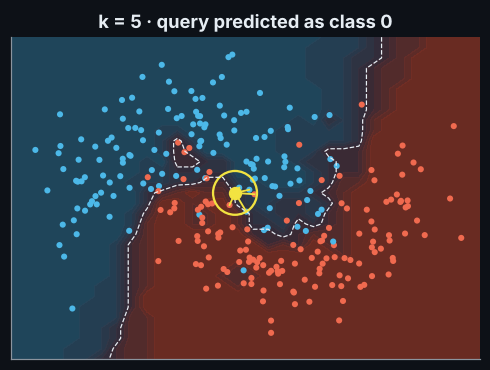

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 3.8))
P.plot_surface(ax, models.knn(5).fit(Xtr, ytr), Xtr, ytr, title=f"k = 5 · query predicted as class {pred[0]}")
ax.add_patch(plt.Circle(q[0], d.max(), fill=False, ec=P.YELLOW, lw=1.5))
for p in Xtr[nn[0]]:
    ax.plot([q[0, 0], p[0]], [q[0, 1], p[1]], c=P.YELLOW, lw=1.2)
ax.scatter(*q[0], s=60, c=P.YELLOW, zorder=5);

## From scratch versus scikit-learn

The two implementations should give identical predictions on the test set (ties are
impossible with odd $k$ and two classes).

In [4]:
for k in models.KNN_KS:
    mine, _ = scratch.knn_predict(Xtr, ytr, Xte, k=k)
    theirs = models.knn(k).fit(Xtr, ytr).predict(Xte)
    print(f"k={k:>2}: identical = {np.array_equal(mine, theirs)}, test accuracy = {np.mean(mine == yte):.3f}")

k= 1: identical = True, test accuracy = 0.892
k= 3: identical = True, test accuracy = 0.883
k= 5: identical = True, test accuracy = 0.908
k=15: identical = True, test accuracy = 0.908
k=45: identical = True, test accuracy = 0.875


## Choosing k: the bias–variance dial

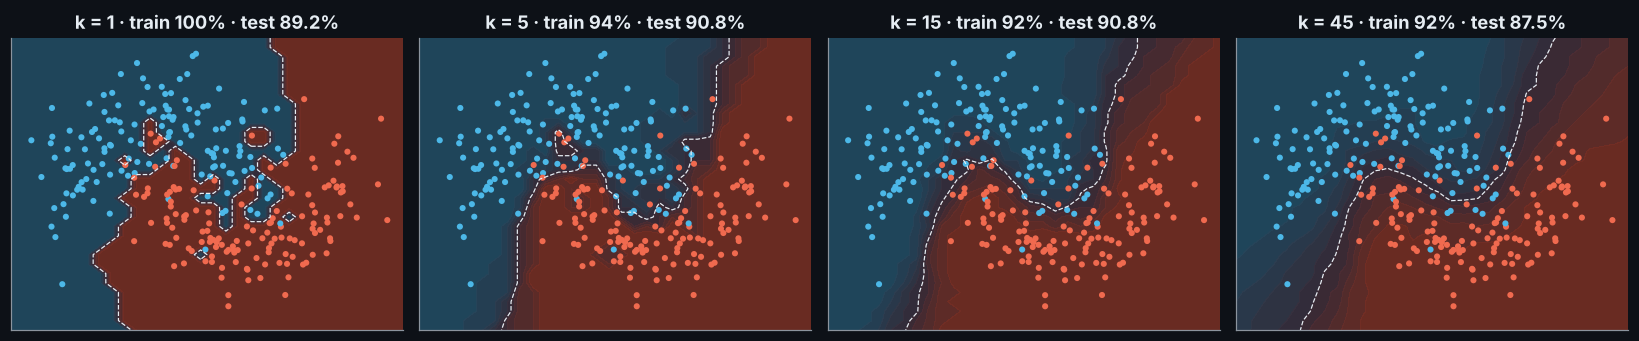

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, k in zip(axes, [1, 5, 15, 45]):
    m = models.knn(k).fit(Xtr, ytr)
    P.plot_surface(ax, m, Xtr, ytr, title=f"k = {k} · train {m.score(Xtr, ytr):.0%} · test {m.score(Xte, yte):.1%}")
plt.tight_layout()

With $k=1$ every training point is its own neighbour, so training accuracy is 100% and
the boundary is ragged (high variance). Large $k$ smooths the boundary until it starts
to ignore the curve of the moons (high bias).

```{important}
Distances mix features directly, so features on different scales must be standardised
first (`StandardScaler`). Both moons features happen to share a scale.
```